# Task 64. Perform CNN on CIFAR-10 Dataset

In [6]:
# ===== Using CNNs to Classify Hand-written Digits on the MNIST Dataset =====
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

# shapes of the dataset
print("X_train shape", X_train.shape)
print("y_train shape", y_train.shape)
print("X_test shape", X_test.shape)
print("y_test shape", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train shape (60000, 28, 28)
y_train shape (60000,)
X_test shape (10000, 28, 28)
y_test shape (10000,)


In [7]:
# ===== A fully connected network on MNIST (baseline) =====
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Conv2D, MaxPool2D, Flatten
from tensorflow.keras.utils import to_categorical

# flatten each 28x28 image into 784 pixels and scale to 0-1
X_train_flat = X_train.reshape(60000, 784).astype('float32') / 255
X_test_flat = X_test.reshape(10000, 784).astype('float32') / 255

# one-hot encode the 10 digit classes
n_classes = 10
Y_train = to_categorical(y_train, n_classes)
Y_test = to_categorical(y_test, n_classes)
print("Shape after one-hot encoding:", Y_train.shape)

tf.random.set_seed(42)
model = Sequential([
    Input(shape=(784,)),
    Dense(100, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
model.fit(X_train_flat, Y_train, batch_size=128, epochs=10, validation_data=(X_test_flat, Y_test))

Shape after one-hot encoding: (60000, 10)
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8962 - loss: 0.3788 - val_accuracy: 0.9419 - val_loss: 0.2041
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9490 - loss: 0.1797 - val_accuracy: 0.9559 - val_loss: 0.1487
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9622 - loss: 0.1319 - val_accuracy: 0.9632 - val_loss: 0.1233
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9702 - loss: 0.1044 - val_accuracy: 0.9677 - val_loss: 0.1080
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9756 - loss: 0.0860 - val_accuracy: 0.9696 - val_loss: 0.0975
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9796 - loss: 0.0723 - val_accuracy: 0.9714 - val_loss: 0.0917
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9826 - loss: 0.0616 - val_accuracy: 0.9721 - val_loss: 0.0874
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy

In [8]:
# ===== CNN model on MNIST =====
# keep the 28x28 image shape and add a channel dimension
X_train_img = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255
X_test_img = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255

tf.random.set_seed(42)
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(25, kernel_size=(3, 3), strides=(1, 1), padding='valid', activation='relu'),
    MaxPool2D(pool_size=(1, 1)),
    Flatten(),
    Dense(100, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
model.fit(X_train_img, Y_train, batch_size=128, epochs=10, validation_data=(X_test_img, Y_test))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9440 - loss: 0.1928 - val_accuracy: 0.9757 - val_loss: 0.0787
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9828 - loss: 0.0578 - val_accuracy: 0.9811 - val_loss: 0.0587
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9908 - loss: 0.0334 - val_accuracy: 0.9828 - val_loss: 0.0521
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9951 - loss: 0.0193 - val_accuracy: 0.9836 - val_loss: 0.0512
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9973 - loss: 0.0117 - val_accuracy: 0.9840 - val_loss: 0.0521
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9981 - loss: 0.0080 - val_accuracy: 0.9839 - val_loss: 0.0573
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9976 - loss: 0.0087 - val_accuracy: 0.9821 - val_loss: 0.0598
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9980 - loss: 0.0065 - val_accuracy: 

In [9]:
# ===== Identifying Images from the CIFAR-10 Dataset using CNNs =====
from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()
print(X_train.shape, X_test.shape)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

(50000, 32, 32, 3) (10000, 32, 32, 3)


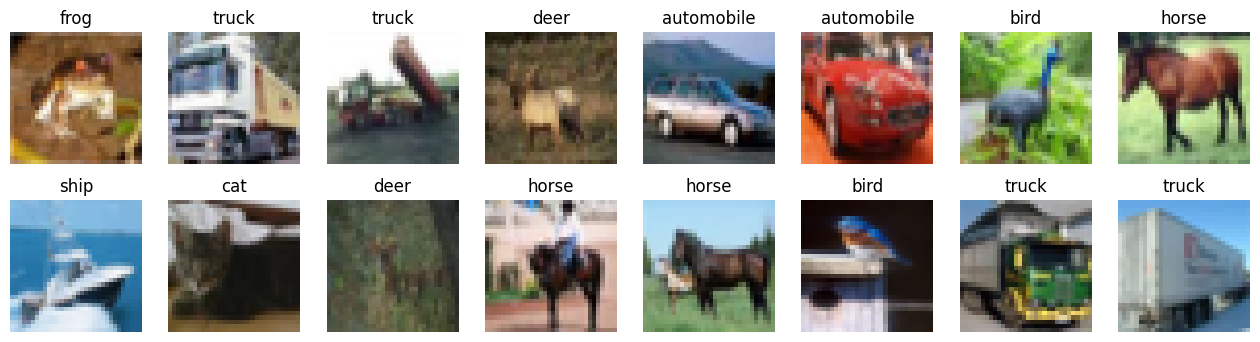

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i])
    ax.set_title(class_names[y_train[i][0]])
    ax.axis('off')
plt.show()

In [11]:
# scale pixels to 0-1 and one-hot encode the labels
from tensorflow.keras.utils import to_categorical

X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
Y_train = to_categorical(y_train, n_classes)
Y_test = to_categorical(y_test, n_classes)

tf.random.set_seed(42)
model = Sequential([
    Input(shape=(32, 32, 3)),
    # convolutional layers
    Conv2D(50, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu'),
    Conv2D(75, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    Dropout(0.25),
    Conv2D(125, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    Dropout(0.25),
    Flatten(),
    # hidden layers
    Dense(500, activation='relu'),
    Dropout(0.4),
    Dense(250, activation='relu'),
    Dropout(0.3),
    # output layer
    Dense(10, activation='softmax')
])
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 50)     │         1,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 75)     │        33,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 75)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 75)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 125)    │        84,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 125)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 125)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 500)            │     4,000,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 250)            │       125,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         2,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,247,985 (16.20 MB)

 Trainable params: 4,247,985 (16.20 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(X_train, Y_train, batch_size=128, epochs=10, validation_data=(X_test, Y_test))

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 33s 55ms/step - accuracy: 0.3914 - loss: 1.6443 - val_accuracy: 0.5702 - val_loss: 1.2194
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.5881 - loss: 1.1505 - val_accuracy: 0.6688 - val_loss: 0.9484
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.6616 - loss: 0.9547 - val_accuracy: 0.7101 - val_loss: 0.8355
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7080 - loss: 0.8297 - val_accuracy: 0.7394 - val_loss: 0.7552
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7390 - loss: 0.7424 - val_accuracy: 0.7504 - val_loss: 0.7236
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7612 - loss: 0.6838 - val_accuracy: 0.7456 - val_loss: 0.7452
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7754 - loss: 0.6315 - val_accuracy: 0.7592 - val_loss: 0.7016
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.7944 - loss: 0.5810 - val_ac

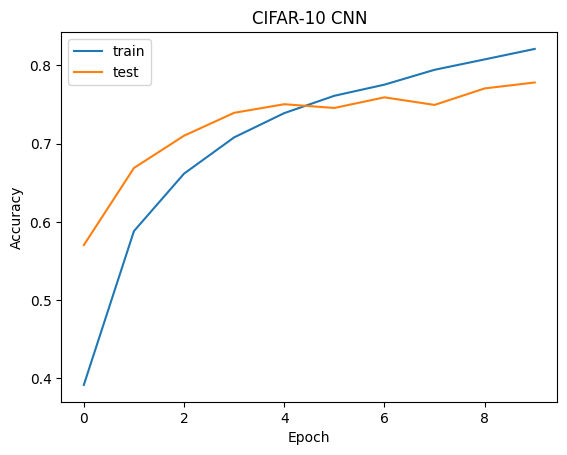

In [13]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CIFAR-10 CNN')
plt.legend();

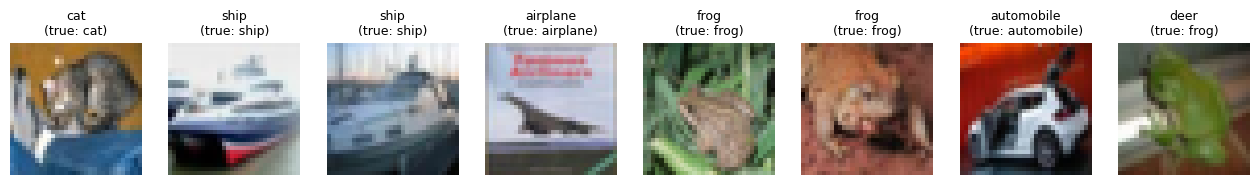

In [14]:
# predictions for a few test images
pred = model.predict(X_test[:8], verbose=0).argmax(axis=1)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(X_test[i])
    ax.set_title(f"{class_names[pred[i]]}\n(true: {class_names[y_test[i][0]]})", fontsize=9)
    ax.axis('off')
plt.show()

## Categorizing the Images of ImageNet using CNNs (Imagenette)
The tutorial uses the full-size Imagenette dataset (1.5 GB, 224x224 images) and trains for 30 epochs.
To run on a CPU, this notebook uses the 160-pixel version of Imagenette (about 100 MB) and fewer epochs.

In [15]:
# ===== Step 1: Download the Imagenette dataset =====
import os
from tensorflow.keras.utils import get_file

archive = get_file('imagenette2-160.tgz',
                   'https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz',
                   extract=True)
data_dir = os.path.join(os.path.dirname(archive), 'imagenette2-160')
if not os.path.isdir(data_dir):   # newer Keras extracts into a folder named after the archive
    data_dir = os.path.join(os.path.dirname(archive), 'imagenette2-160_extracted', 'imagenette2-160')
print(os.listdir(data_dir))

99003388/99003388 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
['.DS_Store', 'noisy_imagenette.csv', 'train', 'val']


In [16]:
# the 10 Imagenette classes and their ImageNet (WordNet) IDs
imagenette_map = {
    "n01440764": "tench",
    "n02102040": "springer",
    "n02979186": "cassette_player",
    "n03000684": "chain_saw",
    "n03028079": "church",
    "n03394916": "French_horn",
    "n03417042": "garbage_truck",
    "n03425413": "gas_pump",
    "n03445777": "golf_ball",
    "n03888257": "parachute"
}

In [17]:
# ===== Step 2: Load the images =====
from tensorflow.keras.utils import image_dataset_from_directory

IMG_SIZE = (160, 160)
train = image_dataset_from_directory(os.path.join(data_dir, 'train'), label_mode='categorical',
                                     image_size=IMG_SIZE, batch_size=128, shuffle=True, seed=42)
val = image_dataset_from_directory(os.path.join(data_dir, 'val'), label_mode='categorical',
                                   image_size=IMG_SIZE, batch_size=128, shuffle=False)
print([imagenette_map[c] for c in train.class_names])

Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
['tench', 'springer', 'cassette_player', 'chain_saw', 'church', 'French_horn', 'garbage_truck', 'gas_pump', 'golf_ball', 'parachute']


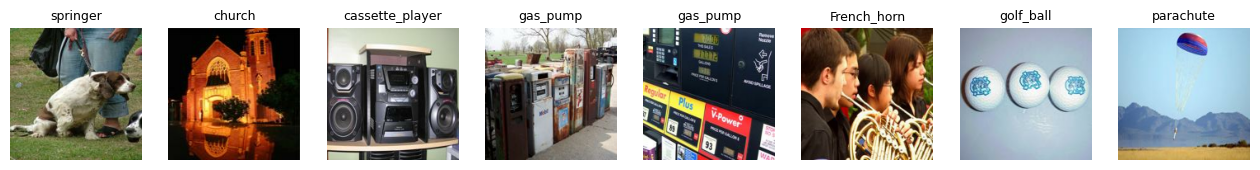

In [18]:
images, labels = next(iter(train))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(images[i].numpy().astype('uint8'))
    ax.set_title(imagenette_map[train.class_names[labels[i].numpy().argmax()]], fontsize=9)
    ax.axis('off')
plt.show()

In [19]:
# ===== Step 3: Build a basic CNN model for image classification =====
from tensorflow.keras.layers import InputLayer, BatchNormalization, Rescaling

tf.random.set_seed(42)
model = Sequential([
    InputLayer(shape=(160, 160, 3)),
    Rescaling(1. / 255),
    Conv2D(25, (5, 5), activation='relu', strides=(1, 1), padding='same'),
    MaxPool2D(pool_size=(2, 2), padding='same'),
    Conv2D(50, (5, 5), activation='relu', strides=(2, 2), padding='same'),
    MaxPool2D(pool_size=(2, 2), padding='same'),
    BatchNormalization(),
    Conv2D(70, (3, 3), activation='relu', strides=(2, 2), padding='same'),
    MaxPool2D(pool_size=(2, 2), padding='valid'),
    BatchNormalization(),
    Flatten(),
    Dense(units=100, activation='relu'),
    Dense(units=100, activation='relu'),
    Dropout(0.25),
    Dense(units=10, activation='softmax')
])
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 25)   │         1,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 80, 80, 25)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 50)     │        31,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 20, 20, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 20, 20, 50)     │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 70)     │        31,570 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 70)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 5, 70)       │           280 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1750)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │       175,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 251,460 (982.27 KB)

 Trainable params: 251,220 (981.33 KB)

 Non-trainable params: 240 (960.00 B)

In [20]:
# 8 epochs instead of the tutorial's 30, to keep the CPU run time reasonable
history = model.fit(train, epochs=8, validation_data=val)

Epoch 1/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 39s 343ms/step - accuracy: 0.3705 - loss: 1.8293 - val_accuracy: 0.1424 - val_loss: 2.1797
Epoch 2/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.5361 - loss: 1.3735 - val_accuracy: 0.2604 - val_loss: 2.0127
Epoch 3/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 8s 102ms/step - accuracy: 0.6341 - loss: 1.1163 - val_accuracy: 0.3259 - val_loss: 1.7864
Epoch 4/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.6968 - loss: 0.9201 - val_accuracy: 0.4456 - val_loss: 1.5226
Epoch 5/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.7560 - loss: 0.7458 - val_accuracy: 0.5294 - val_loss: 1.3885
Epoch 6/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.7985 - loss: 0.6223 - val_accuracy: 0.4250 - val_loss: 2.3374
Epoch 7/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - accuracy: 0.8402 - loss: 0.4980 - val_accuracy: 0.6461 - val_loss: 1.1758
Epoch 8/8
74/74 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8696 - loss: 0.3911 - val_accuracy: 0.6163 - va

In [21]:
# ===== Step 4: Use transfer learning (VGG16) =====
# 1. Download the pre-trained VGG16 weights (without the final classification layers)
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

pretrained_model = VGG16(include_top=False, weights='imagenet', input_shape=(160, 160, 3))
pretrained_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 160, 160, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 160, 160, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 80, 80, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 80, 80, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 40, 40, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 20, 20, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 10, 10, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# 2. Generate features from VGG16 (the training images are read in a fixed order here)
train_fixed = image_dataset_from_directory(os.path.join(data_dir, 'train'), label_mode='categorical',
                                           image_size=IMG_SIZE, batch_size=128, shuffle=False)

vgg_features_train = pretrained_model.predict(train_fixed.map(lambda x, y: preprocess_input(x)))
vgg_features_val = pretrained_model.predict(val.map(lambda x, y: preprocess_input(x)))
print(vgg_features_train.shape, vgg_features_val.shape)

Found 9469 files belonging to 10 classes.
74/74 ━━━━━━━━━━━━━━━━━━━━ 91s 762ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step
(9469, 5, 5, 512) (3925, 5, 5, 512)


In [23]:
# the one-hot targets in the same order as the features
train_target = np.concatenate([y for _, y in train_fixed])
val_target = np.concatenate([y for _, y in val])
print(train_target.shape, val_target.shape)

(9469, 10) (3925, 10)


In [24]:
# 3. Train a small fully connected model on the VGG16 features
tf.random.set_seed(42)
model2 = Sequential([
    Input(shape=vgg_features_train.shape[1:]),
    Flatten(),
    Dense(100, activation='relu'),
    Dropout(0.5),
    BatchNormalization(),
    Dense(10, activation='softmax')
])
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 100)            │     1,280,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281,510 (4.89 MB)

 Trainable params: 1,281,310 (4.89 MB)

 Non-trainable params: 200 (800.00 B)

In [25]:
history2 = model2.fit(vgg_features_train, train_target, epochs=20, batch_size=128,
                      validation_data=(vgg_features_val, val_target))

Epoch 1/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.8961 - loss: 0.3991 - val_accuracy: 0.9460 - val_loss: 0.1680
Epoch 2/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9747 - loss: 0.1252 - val_accuracy: 0.9546 - val_loss: 0.1475
Epoch 3/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9905 - loss: 0.0662 - val_accuracy: 0.9552 - val_loss: 0.1429
Epoch 4/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9955 - loss: 0.0375 - val_accuracy: 0.9539 - val_loss: 0.1411
Epoch 5/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9982 - loss: 0.0264 - val_accuracy: 0.9557 - val_loss: 0.1419
Epoch 6/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9990 - loss: 0.0185 - val_accuracy: 0.9546 - val_loss: 0.1399
Epoch 7/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9992 - loss: 0.0137 - val_accuracy: 0.9567 - val_loss: 0.1388
Epoch 8/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9994 - loss: 0.0109 - val_accuracy: 0.9549 - val_l

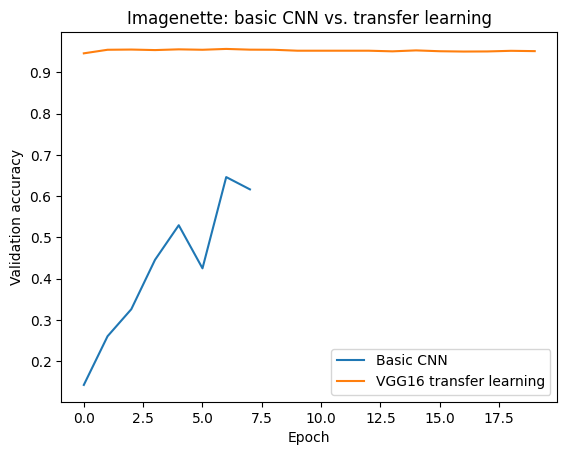

In [26]:
plt.plot(history.history['val_accuracy'], label='Basic CNN')
plt.plot(history2.history['val_accuracy'], label='VGG16 transfer learning')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.title('Imagenette: basic CNN vs. transfer learning')
plt.legend();